# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [1]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [2]:
# Inspect the shapes of the datasets
#
# Important Prepration steps for a classification neural network:
# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


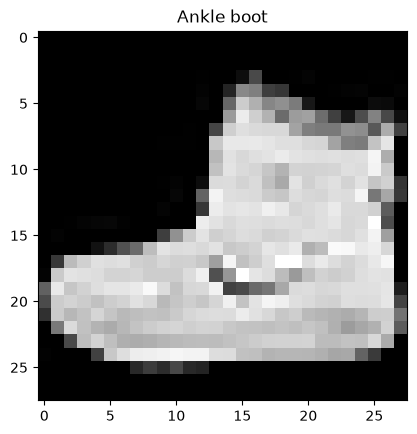

In [3]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
# metplotlib is a python library used for data visualization and graphical plotting. It is a 2D plotting library that can be used to generate publication-quality figures
plt.imshow(X_train[0], cmap='gray')
plt.title(class_names[y_train[0]])
plt.show()


Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here** Data looks like a Image of Ankle boot and quality of Image is very poor. 28x28 pixel value might be some potential reason and this needs to made higher ratio e.g. 56X56 to get bettter resolution and run the model training few time to get better results

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [4]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()
# You can use `model.add(<layer>)` to add layers to the model

# Compile the model using `model.compile()`

# Train the model with `model.fit()`

# Evaluate the model with `model.evaluate()`

In [5]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create model
model = Sequential()

# Convert 28x28 image into 784 values
model.add(Flatten(input_shape=(28, 28)))

# Hidden layer with 128 neurons
model.add(Dense(128, activation='relu'))

# Output layer for 10 clothing categories
model.add(Dense(10, activation='softmax'))

# Configure how the model learns
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
# print("X_train shape:", X_train.shape)
# print("y_train shape:", y_train.shape)
# print("X_train dtype:", X_train.dtype)
#print("y_train dtype:", y_train.dtype)
model.summary()
# Train
model.fit(
    X_train,
    y_train,
    epochs=10
)
# Evaluate
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test accuracy:", test_accuracy)   

c:\Users\usd01056\Documents\GitHub\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.8255 - loss: 0.4977
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8669 - loss: 0.3733
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8763 - loss: 0.3367
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8853 - loss: 0.3124
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8907 - loss: 0.2954
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8956 - loss: 0.2814
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9006 - loss: 0.2676
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9045 - loss: 0.2561
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9081 - loss: 0.2478
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9099 - loss: 0.2384
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8756 - loss: 0.3578
Test accuracy: 0.8755999803543091


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here** Test accuracy was 88.33% with Epoch 10 and loss:0.34. Perforamnce was better then the previous run and improved to 88.47 % and loss:0.32 during the next run


# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [6]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
# Evaluate the model


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Flatten, Dense

# Reshape images for CNN
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create CNN
model = Sequential()

# Extract image features
model.add(
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    )
)

# Convert features into one dimension
model.add(Flatten())

# Classification layer
model.add(Dense(10, activation='softmax'))

# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train
model.fit(
    X_train,
    y_train,
    epochs=10
)

# Evaluate
model.evaluate(
    X_test,
    y_test
)

Epoch 1/10


c:\Users\usd01056\Documents\GitHub\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8521 - loss: 0.4250
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.8928 - loss: 0.2980
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 17s 9ms/step - accuracy: 0.9074 - loss: 0.2582
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9171 - loss: 0.2290
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9258 - loss: 0.2060
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9336 - loss: 0.1842
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9402 - loss: 0.1660
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9457 - loss: 0.1516
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9520 - loss: 0.1357
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9552 - loss: 0.1250
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9004 - loss: 0.3271


[0.32710814476013184, 0.9003999829292297]

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here** CNN Model performed better than baseline model by 7 % ( 88 vs 95). CNN looks for visual pattern first, then classify. This is the key conceptual jump from the basic neural network built earlier vs CNN for Image recognition use case

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [8]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

# Reshape and normalize images
X_train = X_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
X_test = X_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0

model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.fit(X_train, y_train, epochs=10, validation_split=0.1)
model.evaluate(X_test, y_test)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.6603 - loss: 1.0751 - val_accuracy: 0.7512 - val_loss: 0.6671
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7762 - loss: 0.6212 - val_accuracy: 0.7873 - val_loss: 0.5697
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8025 - loss: 0.5541 - val_accuracy: 0.8062 - val_loss: 0.5286
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8153 - loss: 0.5183 - val_accuracy: 0.8203 - val_loss: 0.4971
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8249 - loss: 0.4948 - val_accuracy: 0.8248 - val_loss: 0.4860
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8329 - loss: 0.4777 - val_accuracy: 0.8252 - val_loss: 0.4733
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8383 - loss: 0.4637 - val_accuracy: 0.8387 - val_loss: 0.4578
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8431 - loss: 0.4529

[0.46616777777671814, 0.8342000246047974]

In [ ]:
# A. Test Hyperparameters, experiment is to vary filter count, learning rate, and batch size while keeping the architecture and data fixed. This tests eight combinations.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.callbacks import EarlyStopping
from itertools import product

def build_model(filters, learning_rate):
    model = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(filters, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(10, activation="softmax"),
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

results = []
best_val_accuracy = -1
best_model = None
best_config = None

for filters, learning_rate, batch_size in product(
    [16, 32],
    [0.001, 0.0003],
    [32, 64],
):
    model = build_model(filters, learning_rate)

    history = model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=batch_size,
        validation_split=0.1,
        callbacks=[
            EarlyStopping(
                monitor="val_accuracy",
                patience=2,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    val_accuracy = max(history.history["val_accuracy"])
    config = {
        "filters": filters,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
    }

    results.append((val_accuracy, config))

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model = model
        best_config = config

for val_accuracy, config in sorted(results, reverse=True):
    print(f"val_accuracy={val_accuracy:.4f}  {config}")

print("\nBest configuration:", best_config)
print(f"Best validation accuracy: {best_val_accuracy:.4f}")

test_loss, test_accuracy = best_model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_accuracy:.4f}")

val_accuracy=0.8462  {'filters': 32, 'learning_rate': 0.001, 'batch_size': 32}
val_accuracy=0.8375  {'filters': 16, 'learning_rate': 0.001, 'batch_size': 32}
val_accuracy=0.8277  {'filters': 32, 'learning_rate': 0.001, 'batch_size': 64}
val_accuracy=0.8187  {'filters': 16, 'learning_rate': 0.001, 'batch_size': 64}
val_accuracy=0.8137  {'filters': 32, 'learning_rate': 0.0003, 'batch_size': 32}
val_accuracy=0.7978  {'filters': 16, 'learning_rate': 0.0003, 'batch_size': 32}
val_accuracy=0.7928  {'filters': 32, 'learning_rate': 0.0003, 'batch_size': 64}
val_accuracy=0.7813  {'filters': 16, 'learning_rate': 0.0003, 'batch_size': 64}

Best configuration: {'filters': 32, 'learning_rate': 0.001, 'batch_size': 32}
Best validation accuracy: 0.8462
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8362 - loss: 0.4617
Test accuracy: 0.8362


In [10]:
# B. Test presence or absence of regularization, keeping the architecture and training settings the same and comparing four versions: no regularization, L2, dropout, and both. The code below uses validation accuracy to compare them and evaluates the best version on the test set.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

def build_model(use_l2=False, use_dropout=False):
    regularizer = l2(0.0001) if use_l2 else None

    model = Sequential([
        Input(shape=(28, 28, 1)),
        Conv2D(
            32, (3, 3),
            activation="relu",
            kernel_regularizer=regularizer,
        ),
        MaxPooling2D((2, 2)),
        Flatten(),
    ])

    if use_dropout:
        model.add(Dropout(0.3))

    model.add(Dense(
        10,
        activation="softmax",
        kernel_regularizer=regularizer,
    ))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

experiments = [
    ("No regularization", False, False),
    ("L2", True, False),
    ("Dropout", False, True),
    ("L2 + Dropout", True, True),
]

results = []
best_model = None
best_val_accuracy = -1
best_name = None

for name, use_l2, use_dropout in experiments:
    tf.keras.utils.set_random_seed(42)
    model = build_model(use_l2=use_l2, use_dropout=use_dropout)

    history = model.fit(
        X_train,
        y_train,
        epochs=10,
        batch_size=64,
        validation_split=0.1,
        callbacks=[
            EarlyStopping(
                monitor="val_accuracy",
                patience=2,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    best_epoch = max(
        range(len(history.history["val_accuracy"])),
        key=lambda i: history.history["val_accuracy"][i],
    )
    train_accuracy = history.history["accuracy"][best_epoch]
    val_accuracy = history.history["val_accuracy"][best_epoch]
    val_loss = history.history["val_loss"][best_epoch]

    results.append((name, train_accuracy, val_accuracy, val_loss))

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model = model
        best_name = name

for name, train_acc, val_acc, val_loss in results:
    print(
        f"{name:18} "
        f"train_acc={train_acc:.4f}  "
        f"val_acc={val_acc:.4f}  "
        f"val_loss={val_loss:.4f}"
    )

print(f"\nBest validation result: {best_name}")
print("Test performance:")
best_model.evaluate(X_test, y_test)

No regularization  train_acc=0.8281  val_acc=0.8245  val_loss=0.4816
L2                 train_acc=0.8114  val_acc=0.8085  val_loss=0.7308
Dropout            train_acc=0.8208  val_acc=0.8235  val_loss=0.4774
L2 + Dropout       train_acc=0.8034  val_acc=0.8077  val_loss=0.7339

Best validation result: No regularization
Test performance:
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8173 - loss: 0.5134


[0.5133538842201233, 0.817300021648407]

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here** I tested different hyperparameter settings for the CNN, varying the number of filters, learning rate, and batch size. The best configuration was 32 filters, a learning rate of 0.001, and a batch size of 32. It achieved 84.62% validation accuracy and 83.62% test accuracy, with a test loss of 0.4617.

I also compared models with no regularization, L2 regularization, dropout, and both techniques together. The model without regularization had the best validation result in that experiment. Its test accuracy was 81.73%, with a test loss of 0.5134. So, in this run, adding regularization did not improve the result.

The small difference between the first model’s validation and test accuracy suggests it performed similarly on both datasets. Regularization can help when a model is overfitting, but it may not help when the baseline already generalizes reasonably well.

The best performance I observed was 83.62% test accuracy, using 32 filters, a 0.001 learning rate, a batch size of 32, and no regularization. However, the regularization experiment used a different batch size, so this does not establish that this exact combination is the best in a direct comparison. To confirm that, I would test each regularization option with the same hyperparameters, including batch size 32.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [11]:
# In my experiment, the best observed settings were 32 filters, learning rate 0.001, batch size 32, and no regularization. The code below rebuilds that model and trains it on the full training set for 10 epochs.
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

tf.keras.utils.set_random_seed(42)

# Build the final model with the selected settings
final_model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(10, activation="softmax"),
])

# Compile with the selected learning rate
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Train on the full training set
final_model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
)

# Evaluate on the test set
test_metrics = final_model.evaluate(X_test, y_test, return_dict=True)

print(f"Test loss:     {test_metrics['loss']:.4f}")
print(f"Test accuracy: {test_metrics['accuracy']:.4f}")

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.6625 - loss: 1.0892
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.7731 - loss: 0.6306
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7978 - loss: 0.5620
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8122 - loss: 0.5265
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8216 - loss: 0.5036
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8281 - loss: 0.4873
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8333 - loss: 0.4750
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8372 - loss: 0.4654
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8397 - loss: 0.4576
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8425 - loss: 0.4511
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8318 - loss: 0.4768
Test loss:     0.4768
Test accuracy: 0.

In [12]:
# For additional class-by-class metrics, calculating precision, recall, and F1 score
from sklearn.metrics import classification_report

predictions = final_model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(y_test, y_pred, digits=4))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0     0.7930    0.8160    0.8043      1000
           1     0.9674    0.9510    0.9592      1000
           2     0.6758    0.7610    0.7159      1000
           3     0.8197    0.8590    0.8389      1000
           4     0.7313    0.6830    0.7063      1000
           5     0.9319    0.9300    0.9309      1000
           6     0.5970    0.5170    0.5541      1000
           7     0.9049    0.9320    0.9182      1000
           8     0.9368    0.9340    0.9354      1000
           9     0.9454    0.9350    0.9402      1000

    accuracy                         0.8318     10000
   macro avg     0.8303    0.8318    0.8303     10000
weighted avg     0.8303    0.8318    0.8303     10000



Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here** The final model achieved 83.18% accuracy on the test set, with a test loss of 0.4768 and a macro-average F1 score of 0.8303.Compared with the best result from my hyperparameter experiments, which had 83.62% test accuracy, the final model was 0.44 percentage points lower. This small difference may be due to randomness in model training, such as weight initialization and the order of training examples.

Several choices likely contributed to the final model’s performance. Normalizing the image pixels helped the model train on consistent input values. The convolutional layer learned visual patterns, while max pooling reduced the feature maps before classification. The experiments also suggested that regularization did not improve validation performance for this model. The class-level results were uneven: class 1 had the strongest F1 score (0.9592), while class 6 had the weakest (0.5541), suggesting the model had difficulty distinguishing some classes.

With more time, I would test data augmentation, additional convolutional layers, and different L2 or dropout strengths alongside the best hyperparameters. I would also inspect a confusion matrix to see which classes the model confuses, and repeat the best experiments with several random seeds to check whether the results are consistent.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.